<a href="https://colab.research.google.com/github/tejeswari30/24P31A42C7_DriveReady_OPC_2026/blob/main/Day_6/task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q langgraph langsmith langchain langchain-groq langchain-community wikipedia "arxiv<2.0.0"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [2]:
from typing import Annotated
from typing_extensions import TypedDict

In [3]:
import sys

try:
    import cgi
except ImportError:
    import html
    import types

    cgi = types.ModuleType("cgi")
    cgi.escape = html.escape
    sys.modules["cgi"] = cgi

In [4]:
from langchain_community.utilities import ArxivAPIWrapper, WikipediaAPIWrapper
from langchain_community.tools import ArxivQueryRun, WikipediaQueryRun

/tmp/ipykernel_666/785463749.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities import ArxivAPIWrapper, WikipediaAPIWrapper


In [5]:
arxiv_wrapper = ArxivAPIWrapper(
    top_k_results=1,
    doc_content_chars_max=300
)

arxiv_tool = ArxivQueryRun(api_wrapper=arxiv_wrapper)

api_wrapper = WikipediaAPIWrapper(
    top_k_results=1,
    doc_content_chars_max=300
)

wiki_tool = WikipediaQueryRun(api_wrapper=api_wrapper)

In [6]:
wiki_tool.invoke("who is virat kohli")


'Page: Virat Kohli\nSummary: Virat Kohli (born 5 November 1988) is an Indian international cricketer and former all-format captain of the Indian national team. He is a right-handed batter and an occasional right-arm medium-pace bowler. Considered one of the greatest batters in cricket, he has been acc'

In [7]:
tools = [wiki_tool]

In [8]:
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages: Annotated[list, add_messages]

In [9]:
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(State)

In [10]:
from langchain_groq import ChatGroq

In [11]:
from google.colab import userdata

groq_api_key = userdata.get("GROQ_API_KEY")

In [12]:
llm = ChatGroq(
    groq_api_key=groq_api_key,
    model_name="openai/gpt-oss-120b"
)
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.5', 'langchain': '1.4.8', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x7eb5c5418440>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x7eb5c5418d70>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [13]:
llm_with_tools = llm.bind_tools(tools=tools)

In [14]:
def chatbot(state: State):
    return {
        "messages": [
            llm_with_tools.invoke(state["messages"])
        ]
    }


In [15]:
from langgraph.prebuilt import ToolNode, tools_condition

In [16]:
graph_builder.add_node("chatbot", chatbot)
tool_node = ToolNode(tools=tools)
graph_builder.add_node("tools", tool_node)

In [17]:
graph_builder.add_conditional_edges(
    "chatbot",
    tools_condition,
)

graph_builder.add_edge("tools", "chatbot")

graph_builder.add_edge(START, "chatbot")

In [18]:
graph = graph_builder.compile()

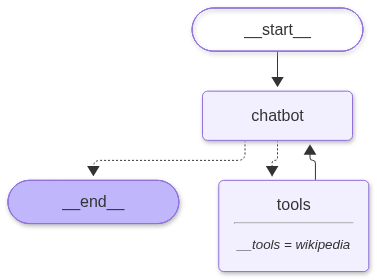

In [19]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    print("Graph visualization is unavailable")

In [20]:
user_input = "Hi there!, My name is Rajesh"

events = graph.stream(
    {"messages": [("user", user_input)]},
    stream_mode="values"
)

for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

Hi there!, My name is Rajesh
================================== Ai Message ==================================

Hello Rajesh! 👋 Nice to meet you. How can I help you today?


In [21]:
graph.stream(
    {"messages": [("user", user_input)]},
    stream_mode="values"
)

<generator object Pregel.stream at 0x318ff690>

In [22]:
for event in events:
    event["messages"][-1].pretty_print()

In [23]:
user_input = "what is RLHF."

events = graph.stream(
    {"messages": [("user", user_input)]},
    stream_mode="values"
)

for event in events:
    event["messages"][-1].pretty_print()


================================ Human Message =================================

what is RLHF.
================================== Ai Message ==================================

**RLHF — Reinforcement Learning from Human Feedback**

---

### 1. What it is
Reinforcement Learning from Human Feedback (RLHF) is a training paradigm that combines **reinforcement learning (RL)** with **human‑generated signals** to shape the behavior of an AI system.  
Instead of relying solely on a hand‑crafted reward function (which is often hard to specify for complex, open‑ended tasks), the system learns a *reward model* that predicts how humans would evaluate its actions, and then uses that model to guide RL.

---

### 2. Why it’s needed
- **Hard‑to‑specify objectives**: For language models, chat assistants, or creative agents, writing a precise reward function that captures “helpful,” “truthful,” “safe,” or “aligned with user intent” is extremely difficult.
- **Safety & alignment**: Human feedback can st

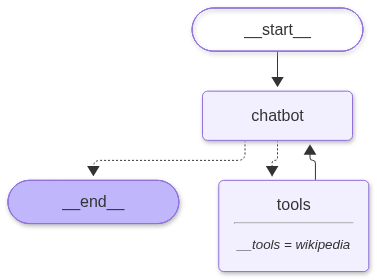

In [24]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass
